In [3]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)
sys.path.append('python-src')
from import_all_notebook_hook import *
import fastbook
fastbook.setup_book()
from fastbook import *

3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


/home/marian/anaconda3/envs/ml/lib/python3.8/site-packages/fastbook/__init__.py:18: UserWarning: Missing `graphviz` - please run `conda install fastbook`
  except ModuleNotFoundError: warn("Missing `graphviz` - please run `conda install fastbook`")


## Already classified 

In [4]:
fns = get_image_files('dataset-cls')
fns

(#3861) [Path('dataset-cls/cls/yes-signature/PDF-3957-51-5-PAG-0-jefe.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3306-51-4-PAG-0-aux1.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3884-51-0-PAG-0-mesa.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3299-51-1-PAG-0-fis2.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3723-51-6-PAG-0-fis3.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3925-51-8-PAG-0-fis1.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3939-51-7-PAG-0-fis1.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3282-51-0-PAG-0-presidente.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3274-51-5-PAG-0-fis1.PNG'),Path('dataset-cls/cls/yes-signature/PDF-3319-51-9-PAG-0-fis2.PNG')...]

## Reconstruct pdf and filter the one that used

In [3]:
def reconstruct_pdf_name(fn): return '-'.join( fn.name.split('-')[1:-3] )+'.pdf'

present_pdfs = { reconstruct_pdf_name(fn) for fn in fns }
present_pdfs

{'3004-51-0.pdf',
 '3005-51-4.pdf',
 '3149-51-4.pdf',
 '3150-51-1.pdf',
 '3151-51-5.pdf',
 '3152-51-9.pdf',
 '3153-51-3.pdf',
 '3156-51-5.pdf',
 '3157-51-9.pdf',
 '3158-51-3.pdf',
 '3160-51-4.pdf',
 '3161-51-8.pdf',
 '3162-51-2.pdf',
 '3163-51-6.pdf',
 '3165-51-4.pdf',
 '3166-51-8.pdf',
 '3172-51-5.pdf',
 '3173-51-9.pdf',
 '3174-51-3.pdf',
 '3175-51-7.pdf',
 '3178-51-9.pdf',
 '3179-51-3.pdf',
 '3180-51-0.pdf',
 '3182-51-8.pdf',
 '3185-51-0.pdf',
 '3190-51-3.pdf',
 '3194-51-9.pdf',
 '3196-51-7.pdf',
 '3197-51-1.pdf',
 '3199-51-9.pdf',
 '3200-51-8.pdf',
 '3203-51-0.pdf',
 '3204-51-4.pdf',
 '3205-51-8.pdf',
 '3206-51-2.pdf',
 '3207-51-6.pdf',
 '3209-51-4.pdf',
 '3211-51-5.pdf',
 '3213-51-3.pdf',
 '3214-51-7.pdf',
 '3217-51-9.pdf',
 '3218-51-3.pdf',
 '3221-51-8.pdf',
 '3222-51-2.pdf',
 '3223-51-6.pdf',
 '3224-51-0.pdf',
 '3226-51-8.pdf',
 '3227-51-2.pdf',
 '3229-51-0.pdf',
 '3230-51-7.pdf',
 '3231-51-1.pdf',
 '3232-51-5.pdf',
 '3266-52-6.pdf',
 '3268-51-8.pdf',
 '3269-51-2.pdf',
 '3272-52-

In [5]:
pdfs=list(telegramas_pdf_generator('./telegramas-urn-sett'))
pdfs=[x for x in pdfs if os.path.basename(x) in present_pdfs]
pdfs

['./telegramas-urn-sett/3/3984-51-2.pdf',
 './telegramas-urn-sett/3/3156-51-5.pdf',
 './telegramas-urn-sett/3/3863-52-6.pdf',
 './telegramas-urn-sett/3/3315-52-9.pdf',
 './telegramas-urn-sett/3/3157-51-9.pdf',
 './telegramas-urn-sett/3/3855-51-5.pdf',
 './telegramas-urn-sett/3/3960-51-0.pdf',
 './telegramas-urn-sett/3/3175-51-7.pdf',
 './telegramas-urn-sett/3/3996-51-3.pdf',
 './telegramas-urn-sett/3/3812-51-1.pdf',
 './telegramas-urn-sett/3/3936-54-3.pdf',
 './telegramas-urn-sett/3/3842-51-0.pdf',
 './telegramas-urn-sett/3/3972-52-7.pdf',
 './telegramas-urn-sett/3/3846-51-6.pdf',
 './telegramas-urn-sett/3/3756-51-7.pdf',
 './telegramas-urn-sett/3/3992-51-7.pdf',
 './telegramas-urn-sett/3/3174-51-3.pdf',
 './telegramas-urn-sett/3/3793-51-7.pdf',
 './telegramas-urn-sett/3/3302-51-8.pdf',
 './telegramas-urn-sett/3/3734-51-3.pdf',
 './telegramas-urn-sett/3/3988-51-8.pdf',
 './telegramas-urn-sett/3/3721-51-8.pdf',
 './telegramas-urn-sett/3/3298-51-7.pdf',
 './telegramas-urn-sett/3/3872-51-

## Do the preprocessing (croping, straight) for this pdfs

In [6]:
f_map = ctx_output_dir(apply_convert_from_path, './telegramas-raw-data')
imgs_fp = parallel_fmap(f_map,list(pdfs))

Are you sure to delete ./telegramas-raw-data? ['yes' for yes]
yes


100%|██████████| 429/429 [02:04<00:00,  3.45it/s]


In [7]:
imgs_fp=flatten(imgs_fp)

In [8]:
imgs_fp

['./telegramas-raw-data/PDF-3984-51-2-PAG-0.png',
 './telegramas-raw-data/PDF-3156-51-5-PAG-0.png',
 './telegramas-raw-data/PDF-3863-52-6-PAG-0.png',
 './telegramas-raw-data/PDF-3315-52-9-PAG-0.png',
 './telegramas-raw-data/PDF-3157-51-9-PAG-0.png',
 './telegramas-raw-data/PDF-3855-51-5-PAG-0.png',
 './telegramas-raw-data/PDF-3960-51-0-PAG-0.png',
 './telegramas-raw-data/PDF-3175-51-7-PAG-0.png',
 './telegramas-raw-data/PDF-3996-51-3-PAG-0.png',
 './telegramas-raw-data/PDF-3812-51-1-PAG-0.png',
 './telegramas-raw-data/PDF-3936-54-3-PAG-0.png',
 './telegramas-raw-data/PDF-3842-51-0-PAG-0.png',
 './telegramas-raw-data/PDF-3972-52-7-PAG-0.png',
 './telegramas-raw-data/PDF-3846-51-6-PAG-0.png',
 './telegramas-raw-data/PDF-3756-51-7-PAG-0.png',
 './telegramas-raw-data/PDF-3992-51-7-PAG-0.png',
 './telegramas-raw-data/PDF-3174-51-3-PAG-0.png',
 './telegramas-raw-data/PDF-3793-51-7-PAG-0.png',
 './telegramas-raw-data/PDF-3302-51-8-PAG-0.png',
 './telegramas-raw-data/PDF-3734-51-3-PAG-0.png',


In [9]:
f_map = apply_preprocess_pipeline
f_map = ctx_output_dir(f_map, './telegramas-crop-imgs')
f_map = ctx_output_dir(f_map, './telegramas-crop-imgs-error')
f_map = functools.partial(f_map, delete_origin=True)
result_paths = parallel_fmap(f_map, imgs_fp)

Are you sure to delete ./telegramas-crop-imgs? ['yes' for yes]
yes
Are you sure to delete ./telegramas-crop-imgs-error? ['yes' for yes]
yes


100%|██████████| 429/429 [04:45<00:00,  1.50it/s]


## Analize how much margin is ok

In [35]:
pth='./dataset-test/crop/1.jpg'

In [37]:
pth=result_paths[0]

In [4]:
pth='preproc-PDF-3992-51-7-PAG-0.png'

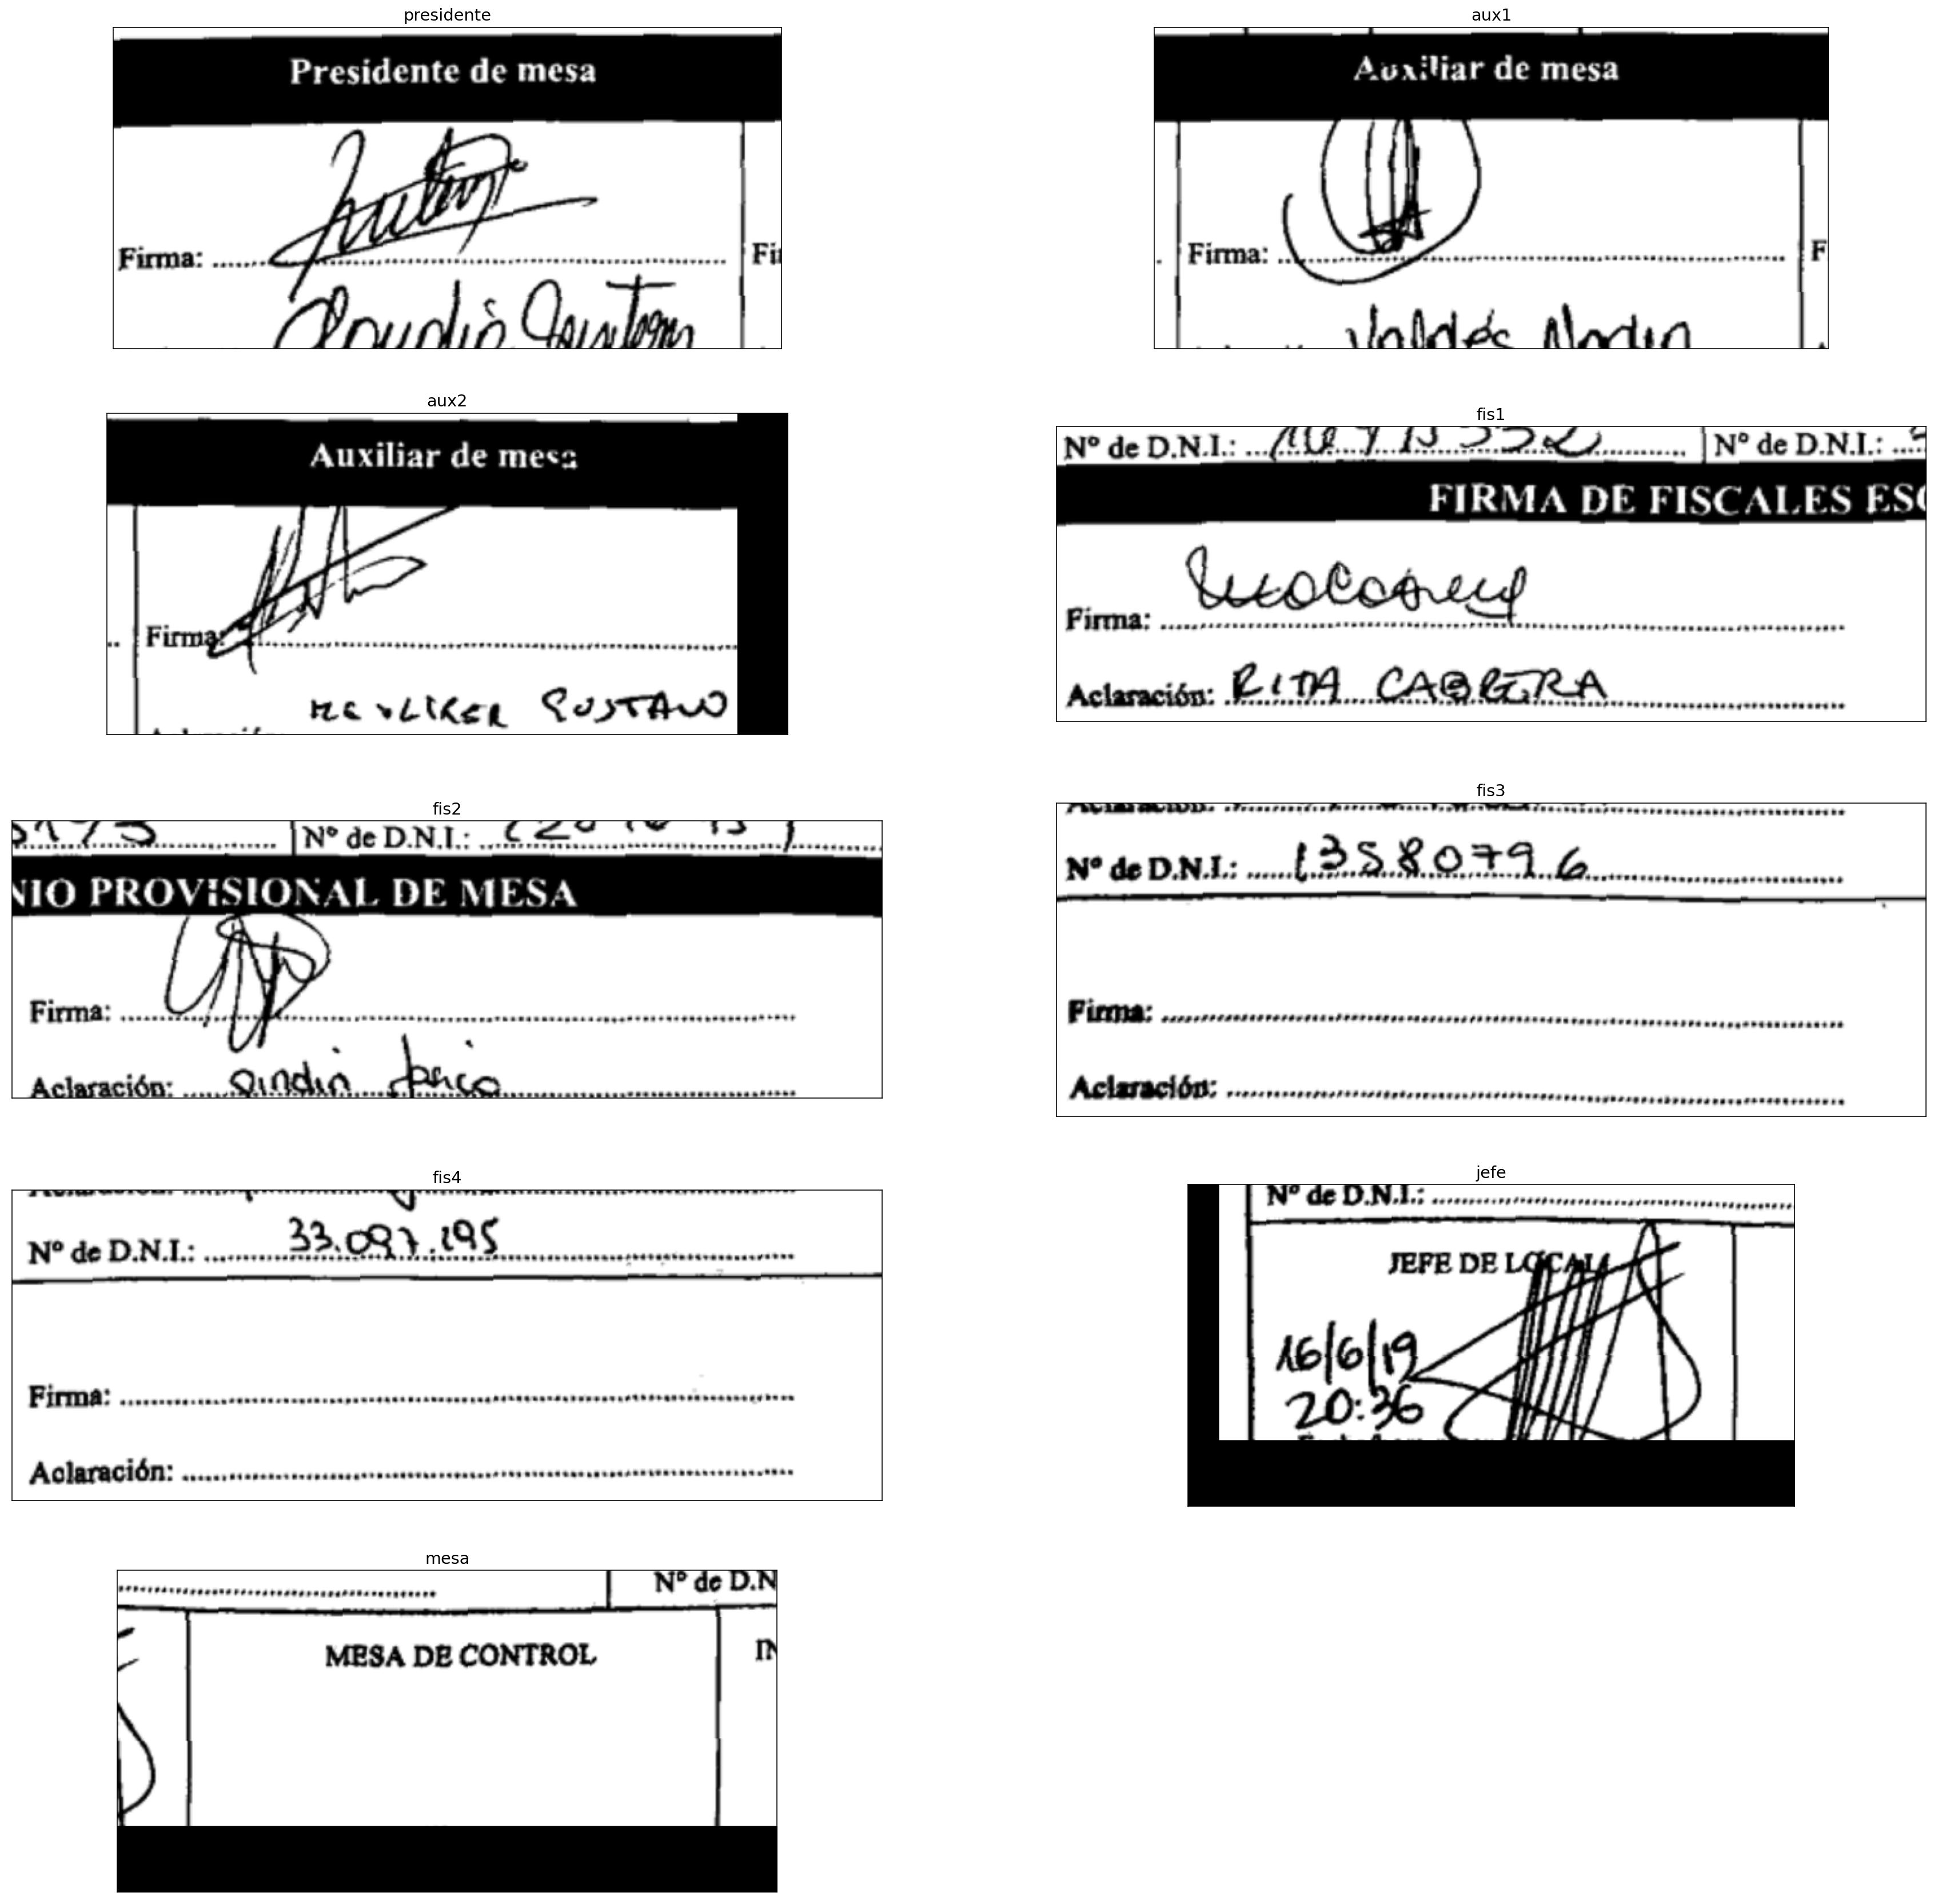

In [7]:
img=Image.open(pth)
nombres,imgs = list(zip(*crop_signatures(img,margin=60)))
plot_images_grid(imgs,2,nombres,figsize=(30,30))

## Extract the signatures with margin

In [3]:
TELEGRAMA_IMG_CROP_PATH='./telegramas-crop-imgs'
result_paths = sorted([os.path.join(TELEGRAMA_IMG_CROP_PATH,fn) for fn in os.listdir(TELEGRAMA_IMG_CROP_PATH)])

In [4]:
f_map = ctx_output_dir(apply_crop_signatures, './signatures')
f_map = functools.partial(f_map, delete_origin=False, margin=60)
signature_paths = parallel_fmap(f_map, result_paths)

Are you sure to delete ./signatures? ['yes' for yes]
yes


100%|██████████| 429/429 [00:21<00:00, 20.35it/s]


## Classify them using the already exist classification

sfns and fns must be a list of signatures paths. 
Each filename in sfns must be in fns and viceversa.
All filepaths must repect that the parent folder name is the class name and the grandparent folder name is the cls / cls_test set

In [3]:
sfns = sorted([os.path.join('./signatures',fn) for fn in os.listdir('./signatures')])

In [5]:
def incl_fns(a,b):
    ss = set(os.path.basename(x) for x in a)
    return [fn for fn in b if os.path.basename(fn) not in ss]

In [6]:
assert len(incl_fns(fns,sfns))==0
assert len(incl_fns(sfns,fns))==0

In [7]:
# Filename -> {yes-signature, no-signature, linea}
fn_to_cls = {Path(fn).name: Path(fn).parent.name for fn in fns}
fn_to_cls

{'PDF-3957-51-5-PAG-0-jefe.PNG': 'yes-signature',
 'PDF-3306-51-4-PAG-0-aux1.PNG': 'yes-signature',
 'PDF-3884-51-0-PAG-0-mesa.PNG': 'yes-signature',
 'PDF-3299-51-1-PAG-0-fis2.PNG': 'yes-signature',
 'PDF-3723-51-6-PAG-0-fis3.PNG': 'yes-signature',
 'PDF-3925-51-8-PAG-0-fis1.PNG': 'yes-signature',
 'PDF-3939-51-7-PAG-0-fis1.PNG': 'yes-signature',
 'PDF-3282-51-0-PAG-0-presidente.PNG': 'yes-signature',
 'PDF-3274-51-5-PAG-0-fis1.PNG': 'yes-signature',
 'PDF-3319-51-9-PAG-0-fis2.PNG': 'yes-signature',
 'PDF-3205-51-8-PAG-0-jefe.PNG': 'yes-signature',
 'PDF-3231-51-1-PAG-0-aux2.PNG': 'yes-signature',
 'PDF-3310-51-3-PAG-0-aux2.PNG': 'yes-signature',
 'PDF-3798-51-7-PAG-0-presidente.PNG': 'yes-signature',
 'PDF-3283-51-4-PAG-0-presidente.PNG': 'yes-signature',
 'PDF-3734-51-3-PAG-0-fis3.PNG': 'yes-signature',
 'PDF-3904-51-8-PAG-0-mesa.PNG': 'yes-signature',
 'PDF-3992-52-3-PAG-0-fis2.PNG': 'yes-signature',
 'PDF-3889-51-0-PAG-0-presidente.PNG': 'yes-signature',
 'PDF-3227-51-2-PAG-0-fis2

In [1]:
# Filename -> {cls, cls_test}
fn_to_ds = {Path(fn).name: Path(fn).parent.parent.name for fn in fns}
fn_to_ds

NameError: name 'fns' is not defined

In [10]:
for x in sfns:
    nx = Path(x).parent / fn_to_ds[Path(x).name] / fn_to_cls[Path(x).name] / Path(x).name
    shutil.copyfile(x,create_if_not_exists(nx))

In [30]:
Path(sfns[0])

Path('signatures/PDF-3004-51-0-PAG-0-aux1.PNG')

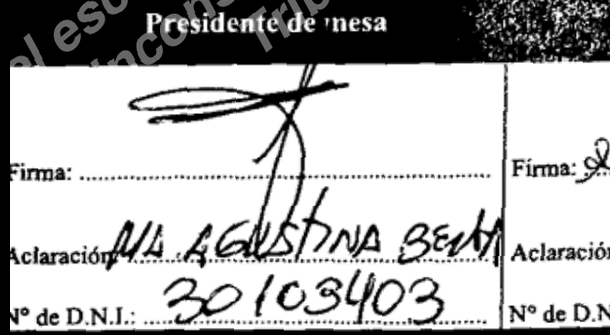

In [29]:
imgs[0]

In [31]:
pdfs

[]

In [35]:
fns=get_image_files('dataset-cls/cls_test')

## Re classification work here:

In [36]:
for p in [75,90,95]:
    for fn in fns:
        img = Image.open(fn)
        nimg = noisify(img,0.75)
        new_fn = str(fn).replace('dataset-cls', 'dataset-noisy-'+str(p))
        nimg.save(create_if_not_exists(new_fn),'png')